# EfficientNet B0-B7 — Compound Model Scaling

**Paper:** Tan, M. & Le, Q. V. (2019).  
*EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.*  
International Conference on Machine Learning (ICML 2019).  
arXiv:1905.11946. [[PDF]](https://arxiv.org/abs/1905.11946)

---

## Overview

EfficientNet introduces **compound scaling**: a principled method to simultaneously scale
width, depth, and resolution of a CNN using a single compound coefficient φ.

Key observation: naively scaling only one dimension (depth OR width OR resolution) is
suboptimal.  Scaling all three in balance yields better accuracy for the same FLOP budget.

**Components:**
- **MBConv** (Mobile Inverted Bottleneck Conv): building block from MobileNetV2 + SE
- **NAS baseline (B0)**: found via Neural Architecture Search on ImageNet
- **B1-B7**: compound-scaled variants with increasing accuracy and parameter count

> Note: This is the **original EfficientNet** (B-series).  
> EfficientNetV2 (`efficientnet_v2.py`) is a later, improved version with FusedMBConv.

> 📄 **Paper:** Tan & Le (2019). EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks. ICML 2019.
> 🔗 **Link:** <https://arxiv.org/abs/1905.11946>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/efficientnet_b.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["conv 3×3 /2 · BN · SiLU → 32"]:::stage
  STEM --> S["7 MBConv stages (k3/k5, expand 1 or 6)<br/>16 · 24 · 40 · 80 · 112 · 192 · 320"]:::stage --> HEAD["1×1 conv → 1280 · BN · SiLU"]:::block --> GAP["avg pool"]:::block --> OUT
  subgraph MB["MBConv + SE"]
    direction LR
    X["x"] --> E["1×1 expand ×6 · BN · SiLU"]:::block --> DW["k×k depthwise · BN · SiLU"]:::block --> SE["squeeze-excite"]:::block --> P["1×1 project · BN"]:::block --> ADD(("+ drop-path"))
    X --> ADD
  end
  S -.-> MB
  SCALE["compound scaling: depth α^φ, width β^φ, resolution γ^φ (B0 → B7)"]:::block -.-> S
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture (ASCII)

```
Input [B, 3, H, W]   (H=W=224 for B0)
    │
    ▼
  Stem: Conv(3→32, 3×3, s2) + BN + SiLU    → [B, 32, H/2, W/2]
    │
    ├─ Stage 1: MBConv1, k=3, s=1, out=16,  rep=1
    ├─ Stage 2: MBConv6, k=3, s=2, out=24,  rep=2  ← stride-8
    ├─ Stage 3: MBConv6, k=5, s=2, out=40,  rep=2  ← stride-16
    ├─ Stage 4: MBConv6, k=3, s=2, out=80,  rep=3
    ├─ Stage 5: MBConv6, k=5, s=1, out=112, rep=3  ← stride-16
    ├─ Stage 6: MBConv6, k=5, s=2, out=192, rep=4  ← stride-32
    └─ Stage 7: MBConv6, k=3, s=1, out=320, rep=1  ← stride-32
    │
    ▼
  Head: Conv(→1280, 1×1) + BN + SiLU → GlobalAvgPool → Dropout → [B, 1280]

MBConv6 internals:
  in → Expand 1×1(×6) → BN → SiLU
      → DW k×k         → BN → SiLU
      → SE(ratio=0.25)
      → Project 1×1    → BN
      → (+ skip if stride=1 and in==out)
```

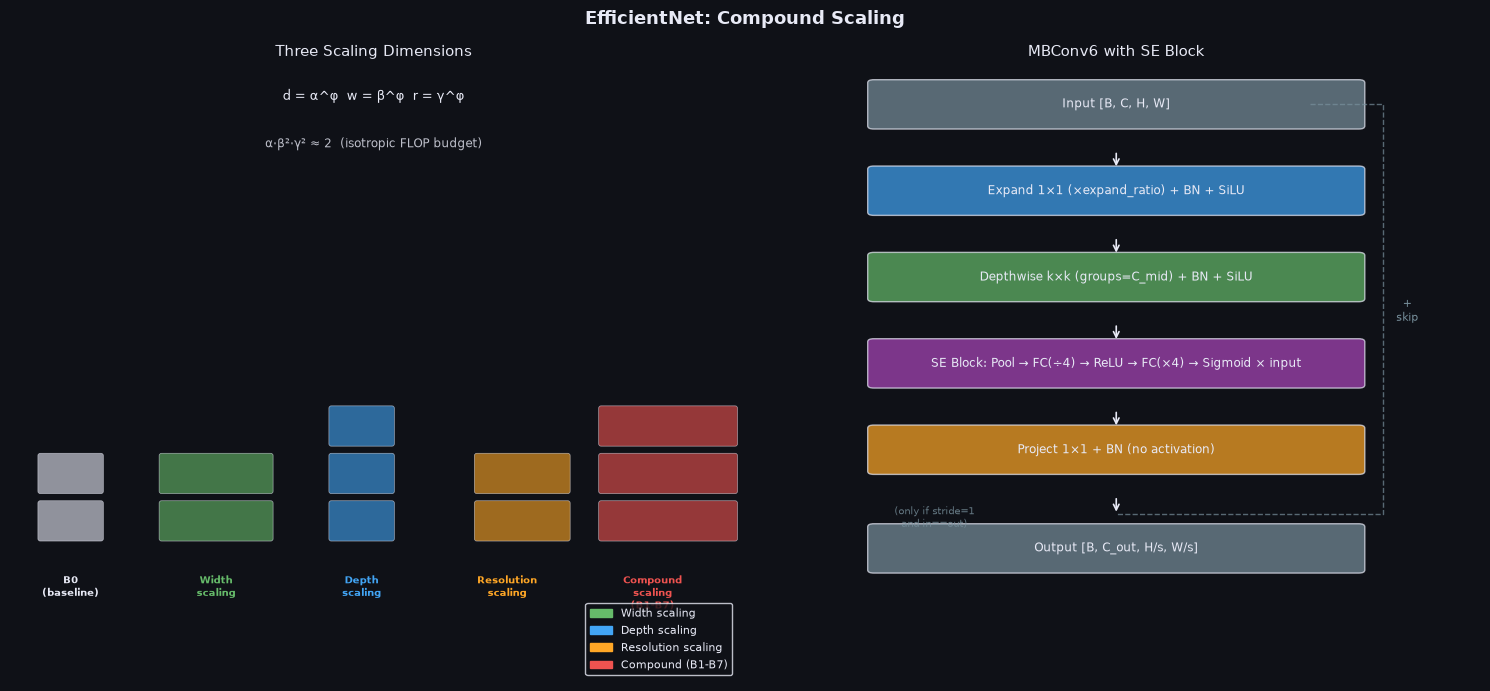

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np

BG   = '#0f1117'
FG   = '#e8eaf6'
DEPTH  = '#42a5f5'
WIDTH  = '#66bb6a'
RES    = '#ffa726'
COMP   = '#ef5350'

fig, axes = plt.subplots(1, 2, figsize=(15, 7), facecolor=BG)
fig.suptitle('EfficientNet: Compound Scaling', color=FG, fontsize=13, fontweight='bold')

# ── Left: Scaling dimensions ──────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Three Scaling Dimensions', color=FG, fontsize=11)

variants = ['B0\n(baseline)', 'Width\nscaling', 'Depth\nscaling', 'Resolution\nscaling', 'Compound\nscaling\n(B1-B7)']
# Represent as (width, depth, res) circles at positions
cols   = [0.5, 1.7, 2.9, 4.1, 5.3]
widths = [0.5, 0.9, 0.5, 0.5, 0.85]
depths = [2,   2,   3.5, 2,   3.0]
reses  = [1.0, 1.0, 1.0, 1.5, 1.3]
colors = [FG,  WIDTH, DEPTH, RES, COMP]

for i, (name, cx, w, d, r, c) in enumerate(zip(variants, cols, widths, depths, reses, colors)):
    # Draw network layers as rectangle stack
    for layer in range(int(d)):
        rect = FancyBboxPatch((cx - w/2, layer*0.4), w*r, 0.3,
                              boxstyle='round,pad=0.02', fc=c, alpha=0.6, ec=FG, lw=0.5)
        ax.add_patch(rect)
    ax.text(cx, -0.3, name, ha='center', va='top', color=c, fontsize=7.5, fontweight='bold')

ax.set_xlim(0, 6); ax.set_ylim(-1.2, 4)
ax.text(3.0, 3.7, 'd = α^φ  w = β^φ  r = γ^φ', ha='center', color=FG, fontsize=9)
ax.text(3.0, 3.3, 'α·β²·γ² ≈ 2  (isotropic FLOP budget)', ha='center', color=FG, fontsize=8.5, alpha=0.8)

legend_handles = [
    mpatches.Patch(color=WIDTH, label='Width scaling'),
    mpatches.Patch(color=DEPTH, label='Depth scaling'),
    mpatches.Patch(color=RES,   label='Resolution scaling'),
    mpatches.Patch(color=COMP,  label='Compound (B1-B7)'),
]
ax.legend(handles=legend_handles, loc='lower right',
          facecolor=BG, edgecolor=FG, labelcolor=FG, fontsize=8)

# ── Right: MBConv block detail ────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.set_xlim(0, 6); ax2.set_ylim(0, 10); ax2.axis('off')
ax2.set_title('MBConv6 with SE Block', color=FG, fontsize=11)

EXP  = '#42a5f5'
DW   = '#66bb6a'
SEL  = '#ab47bc'
PRJ  = '#ffa726'
SKP  = '#78909c'

def box2(y, text, color, alpha=0.7, w=4.0):
    x = (6-w)/2
    ax2.add_patch(FancyBboxPatch((x, y), w, 0.7, boxstyle='round,pad=0.05', fc=color, alpha=alpha, ec=FG, lw=1))
    ax2.text(3.0, y+0.35, text, ha='center', va='center', color=FG, fontsize=8.5)

def arr2(y):
    ax2.annotate('', xy=(3.0, y), xytext=(3.0, y+0.3), arrowprops=dict(arrowstyle='->', color=FG, lw=1.2))

box2(9.0, 'Input [B, C, H, W]', SKP)
arr2(8.3)
box2(7.6, 'Expand 1×1 (×expand_ratio) + BN + SiLU', EXP)
arr2(6.9)
box2(6.2, 'Depthwise k×k (groups=C_mid) + BN + SiLU', DW)
arr2(5.5)
box2(4.8, 'SE Block: Pool → FC(÷4) → ReLU → FC(×4) → Sigmoid × input', SEL)
arr2(4.1)
box2(3.4, 'Project 1×1 + BN (no activation)', PRJ)
arr2(2.7)

# Skip connection
ax2.plot([4.6, 5.2, 5.2, 3.0], [9.35, 9.35, 2.7, 2.7], color=SKP, lw=1, linestyle='dashed', alpha=0.7)
ax2.text(5.4, 6.0, '+\nskip', ha='center', va='center', color=SKP, fontsize=8)
ax2.text(1.5, 2.5, '(only if stride=1\nand in==out)', ha='center', color=SKP, fontsize=7.5, alpha=0.8)

box2(1.8, 'Output [B, C_out, H/s, W/s]', SKP)

plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations & Mathematics

### Compound Scaling Principle

Given a baseline network $\mathcal{N}$, scale width $w$, depth $d$, resolution $r$ to maximise accuracy subject to a FLOP constraint:

$$\mathcal{N}(d, w, r) = \mathcal{N}(\alpha^\phi, \beta^\phi, \gamma^\phi)$$

Subject to:
$$\alpha \cdot \beta^2 \cdot \gamma^2 \approx 2, \quad \alpha \geq 1, \beta \geq 1, \gamma \geq 1$$

The $\beta^2$ and $\gamma^2$ terms account for the quadratic FLOP dependence on width and resolution.

B0 baseline coefficients (from NAS): $\alpha=1.2, \beta=1.1, \gamma=1.15$.

### Compound Scaling Multipliers

| Model | φ | Width | Depth | Resolution | Top-1 |
|-------|---|-------|-------|------------|-------|
| B0 | 0 | 1.0 | 1.0 | 224 | 77.1% |
| B1 | 0.5 | 1.0 | 1.1 | 240 | 79.1% |
| B2 | 1 | 1.1 | 1.2 | 260 | 80.1% |
| B3 | 2 | 1.2 | 1.4 | 300 | 81.6% |
| B4 | 3 | 1.4 | 1.8 | 380 | 82.9% |
| B7 | 6 | 2.0 | 3.1 | 600 | 84.3% |

### MBConv FLOP Cost

For MBConv with expansion ratio $t$, input channels $C_i$, output $C_o$, spatial $H \times W$:

$$\text{FLOPs} \approx H \cdot W \cdot C_i \cdot t \cdot C_i \quad \text{(expand)} + H \cdot W \cdot k^2 \cdot t \cdot C_i \quad \text{(depthwise)} + H \cdot W \cdot t \cdot C_i \cdot C_o \quad \text{(project)}$$

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/efficientnet_b.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/efficientnet_b.py</code></summary>

```text
EfficientNet B0-B7 Vision Backbones
======================================

Implements the original EfficientNet family (Tan & Le 2019, "EfficientNet:
Rethinking Model Scaling for Convolutional Neural Networks", ICML 2019).

Reference: https://arxiv.org/abs/1905.11946

Architecture
------------
EfficientNet introduces **compound scaling**: width, depth and input resolution
are scaled simultaneously using a single compound coefficient φ:

    depth    d = α^φ
    width    w = β^φ
    resolution r = γ^φ

Subject to: α × β² × γ² ≈ 2, α≥1, β≥1, γ≥1.
B0 baseline found via NAS; B1-B7 apply compound scaling.

Building block: **MBConv** (Mobile Inverted Bottleneck Convolution) with SE:
  input → expand 1×1 (ratio r) → BN → SiLU
        → depthwise k×k        → BN → SiLU
        → SE(reduction=4)
        → project 1×1          → BN
        → (+residual if stride=1 and in_chs==out_chs)

B0 baseline stage layout (Table 1 of paper):
  Stage 1 : MBConv1, k=3, s=1, out=16,  repeat=1
  Stage 2 : MBConv6, k=3, s=2, out=24,  repeat=2
  Stage 3 : MBConv6, k=5, s=2, out=40,  repeat=2
  Stage 4 : MBConv6, k=3, s=2, out=80,  repeat=3
  Stage 5 : MBConv6, k=5, s=1, out=112, repeat=3
  Stage 6 : MBConv6, k=5, s=2, out=192, repeat=4
  Stage 7 : MBConv6, k=3, s=1, out=320, repeat=1
  Head    : Conv 1×1 → 1280 → GlobalAvgPool → dropout → embedding

Multi-scale feature map outputs:
  feature_maps[0]: stride-4  (after stem)
  feature_maps[1]: stride-8  (after stage 2)
  feature_maps[2]: stride-16 (after stage 4)
  feature_maps[3]: stride-32 (after stage 6+7+head)

Compound scaling multipliers (from paper Table 2):
  B0: depth=1.0, width=1.0, res=224
  B1: depth=1.1, width=1.0, res=240
  B2: depth=1.2, width=1.1, res=260
  B3: depth=1.4, width=1.2, res=300
  B4: depth=1.8, width=1.4, res=380
  B5: depth=2.2, width=1.6, res=456
  B6: depth=2.6, width=1.8, res=528
  B7: depth=3.1, width=2.0, res=600

Registered names
----------------
  efficientnet_b0  — ~5.3M params
  efficientnet_b1  — ~7.8M params
  efficientnet_b2  — ~9.1M params
  efficientnet_b3  — ~12M params
  efficientnet_b4  — ~19M params
  efficientnet_b5  — ~30M params
  efficientnet_b6  — ~43M params
  efficientnet_b7  — ~66M params

Note: This is the ORIGINAL EfficientNet (B-series).  EfficientNetV2 is a
separate architecture in efficientnet.py (uses FusedMBConv blocks).

Citation
--------
  Tan, M. & Le, Q. V. (2019). EfficientNet: Rethinking Model Scaling for
  Convolutional Neural Networks. ICML. arXiv:1905.11946.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/efficientnet_b.py`, definition by definition

In [5]:
def _make_divisible(v: float, divisor: int = 8) -> int:
    """Round v up to the nearest multiple of divisor (min=divisor)."""
    return max(divisor, int(v + divisor / 2) // divisor * divisor)

**`StochasticDepth`** - Randomly drops residual branches during training (Huang et al. 2016).

In [6]:
class StochasticDepth(nn.Module):
    """Randomly drops residual branches during training (Huang et al. 2016).

    At test time, the residual branch is always active (no scaling needed;
    the expected value is preserved by the Bernoulli / survival probability).
    """

    def __init__(self, drop_prob: float = 0.0) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        survival = 1.0 - self.drop_prob
        noise = torch.empty(x.shape[0], 1, 1, 1, device=x.device, dtype=x.dtype)
        noise.bernoulli_(survival).div_(survival)
        return x * noise

**`SqueezeExciteB`** - SE block for EfficientNet-B with SiLU activations.

In [7]:
class SqueezeExciteB(nn.Module):
    """SE block for EfficientNet-B with SiLU activations.

    Args:
        in_chs:       Input (and output) channel count.
        se_ratio:     Reduction ratio applied to in_chs.  Default 0.25 (paper: 0.25).
    """

    def __init__(self, in_chs: int, se_ratio: float = 0.25) -> None:
        super().__init__()
        squeezed = max(1, int(in_chs * se_ratio))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc1  = nn.Conv2d(in_chs, squeezed, kernel_size=1, bias=True)
        self.fc2  = nn.Conv2d(squeezed, in_chs, kernel_size=1, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        s = self.pool(x)
        s = F.silu(self.fc1(s))
        s = torch.sigmoid(self.fc2(s))
        return x * s

**`MBConvB`** - Mobile Inverted Bottleneck Conv for EfficientNet-B series.

In [8]:
class MBConvB(nn.Module):
    """Mobile Inverted Bottleneck Conv for EfficientNet-B series.

    When expand_ratio=1 the expansion 1×1 conv is skipped (no channel change).
    SE is applied to the expanded (depthwise) channel count, not the input count.
    This differs from SE-ResNet where SE is applied to the bottleneck output.

    Args:
        in_chs:       Input channels.
        out_chs:      Output channels.
        stride:       Spatial stride (1 or 2).
        expand_ratio: Channel expansion before depthwise (typically 6, or 1 for first stage).
        kernel_size:  Depthwise conv kernel size (3 or 5).
        se_ratio:     SE reduction ratio relative to expanded channels.
        drop_path:    Stochastic depth probability.
    """

    def __init__(
        self,
        in_chs:       int,
        out_chs:      int,
        stride:       int   = 1,
        expand_ratio: int   = 6,
        kernel_size:  int   = 3,
        se_ratio:     float = 0.25,
        drop_path:    float = 0.0,
    ) -> None:
        super().__init__()
        mid_chs  = _make_divisible(in_chs * expand_ratio, 8)
        has_skip = stride == 1 and in_chs == out_chs
        pad      = (kernel_size - 1) // 2

        layers: list[nn.Module] = []

        # Expansion phase (skip when ratio=1 — nothing changes channel-wise)
        if expand_ratio != 1:
            layers += [
                nn.Conv2d(in_chs, mid_chs, kernel_size=1, bias=False),
                nn.BatchNorm2d(mid_chs),
                nn.SiLU(inplace=True),
            ]
        else:
            mid_chs = in_chs   # no expansion

        # Depthwise conv
        layers += [
            nn.Conv2d(mid_chs, mid_chs, kernel_size=kernel_size,
                      stride=stride, padding=pad, groups=mid_chs, bias=False),
            nn.BatchNorm2d(mid_chs),
            nn.SiLU(inplace=True),
        ]

        # Squeeze-Excite on expanded channels
        if se_ratio > 0.0:
            layers.append(SqueezeExciteB(mid_chs, se_ratio=se_ratio))

        # Projection
        layers += [
            nn.Conv2d(mid_chs, out_chs, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_chs),
        ]

        self.conv      = nn.Sequential(*layers)
        self.drop_path = StochasticDepth(drop_path) if has_skip else nn.Identity()
        self.has_skip  = has_skip

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.has_skip:
            return x + self.drop_path(self.conv(x))
        return self.conv(x)

**`_B0StageConfig`** - B0 baseline specification for one stage.

In [9]:
@dataclass
class _B0StageConfig:
    """B0 baseline specification for one stage."""
    expand_ratio: int
    kernel_size:  int
    stride:       int
    out_chs:      int   # baseline (B0) output channels
    num_blocks:   int   # baseline (B0) repeat count

In [10]:
# B0 stage definitions from Table 1 of the EfficientNet paper
_B0_STAGES: list[_B0StageConfig] = [
    _B0StageConfig(1, 3, 1, 16,  1),  # Stage 1: MBConv1
    _B0StageConfig(6, 3, 2, 24,  2),  # Stage 2: MBConv6
    _B0StageConfig(6, 5, 2, 40,  2),  # Stage 3: MBConv6 k=5
    _B0StageConfig(6, 3, 2, 80,  3),  # Stage 4: MBConv6
    _B0StageConfig(6, 5, 1, 112, 3),  # Stage 5: MBConv6 k=5
    _B0StageConfig(6, 5, 2, 192, 4),  # Stage 6: MBConv6 k=5
    _B0StageConfig(6, 3, 1, 320, 1),  # Stage 7: MBConv6
]

**`EfficientNetB`** - Original EfficientNet B0-B7 backbone.

In [11]:
class EfficientNetB(BaseVisionBackbone):
    """Original EfficientNet B0-B7 backbone.

    Scales the B0 baseline architecture using compound depth/width multipliers.
    Returns a 4-scale feature pyramid compatible with FPN/BEV heads.

    The feature pyramid groups stages by their spatial stride:
      feature_maps[0] → stride 4  (stem output)
      feature_maps[1] → stride 8  (after first stride-2 stage)
      feature_maps[2] → stride 16 (after second stride-2 stage)
      feature_maps[3] → stride 32 (after third stride-2 stage + remaining stages + head)

    Args:
        depth_mult:   Depth scaling factor (multiplies num_blocks per stage).
        width_mult:   Width scaling factor (multiplies channel counts).
        head_chs:     Head 1×1 conv output channels (default 1280).
        drop_path_rate: Max stochastic depth rate.
        dropout_rate: Classifier dropout (applied to pooled embedding).
        img_size, in_chans, drop_rate, out_indices: See BaseVisionBackbone.
    """

    arch_name:    str       = "efficientnet_b"
    embed_dim:    int       = 1280
    feature_dims: list[int] = []

    def __init__(
        self,
        depth_mult:     float = 1.0,
        width_mult:     float = 1.0,
        head_chs:       int   = 1280,
        drop_path_rate: float = 0.2,
        img_size:       int   = 224,
        in_chans:       int   = 3,
        drop_rate:      float = 0.2,
        out_indices:    list[int] | None = None,
    ) -> None:
        self.embed_dim = head_chs
        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        def _w(c: int) -> int:
            return _make_divisible(c * width_mult, 8)

        def _d(n: int) -> int:
            return max(1, math.ceil(n * depth_mult))

        # ── Stem: stride-2, 3→stem_chs ───────────────────────────────────────
        stem_chs = _w(32)
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, stem_chs, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(stem_chs),
            nn.SiLU(inplace=True),
        )

        # ── Build scaled stages ───────────────────────────────────────────────
        total_blocks = sum(_d(s.num_blocks) for s in _B0_STAGES)
        block_idx    = 0

        # Group blocks by feature map scale (stride-2 transitions)
        # Groups: [stem→s1], [s2], [s3], [s4+s5+s6+s7+head]
        # stride-2 stages: 2 (24ch), 3 (40ch), 4 (80ch), 6 (192ch)
        # We track stride to assign blocks to feature pyramid levels.
        stride_groups: list[list[nn.Module]] = [[] for _ in range(4)]
        current_group = 0
        stride_counts = [0]   # cumulative stride-doublings seen so far

        in_chs = stem_chs
        stride_2_seen = 0

        stage_modules: list[nn.Sequential] = []

        for s in _B0_STAGES:
            out_chs    = _w(s.out_chs)
            num_blocks = _d(s.num_blocks)
            stage_blks: list[nn.Module] = []

            for i in range(num_blocks):
                dp   = drop_path_rate * block_idx / max(total_blocks - 1, 1)
                blk  = MBConvB(
                    in_chs=in_chs,
                    out_chs=out_chs,
                    stride=s.stride if i == 0 else 1,
                    expand_ratio=s.expand_ratio,
                    kernel_size=s.kernel_size,
                    se_ratio=0.25,
                    drop_path=dp,
                )
                stage_blks.append(blk)
                in_chs = out_chs
                block_idx += 1

            stage_modules.append(nn.Sequential(*stage_blks))
            if s.stride == 2:
                stride_2_seen += 1

        self.stages = nn.ModuleList(stage_modules)

        # ── Head conv ─────────────────────────────────────────────────────────
        self.head_conv = nn.Sequential(
            nn.Conv2d(in_chs, head_chs, kernel_size=1, bias=False),
            nn.BatchNorm2d(head_chs),
            nn.SiLU(inplace=True),
        )
        self.pool      = nn.AdaptiveAvgPool2d(1)
        self.head_drop = nn.Dropout(drop_rate)

        # Feature dims: output channels of stride-2 transition stages + head
        # Stages with stride=2: indices 1, 2, 3, 5 in _B0_STAGES (0-indexed)
        stride2_stages = [i for i, s in enumerate(_B0_STAGES) if s.stride == 2]
        # feature_dims[0] = channels after stem (stride-4)
        # feature_dims[1..3] = channels after each of the first 3 stride-2 stages
        stride2_chs = [_w(_B0_STAGES[i].out_chs) for i in stride2_stages[:3]]
        self.feature_dims = [stem_chs] + stride2_chs + [head_chs]
        # Trim to 4 levels
        self.feature_dims = self.feature_dims[:4]

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run EfficientNet-B forward pass.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, head_chs]
              feature_maps  — 4-scale pyramid
        """
        # Stem output: stride-4 (first feature map level)
        x = self.stem(x)
        feature_maps: list[torch.Tensor] = [x]

        stride_count = 0
        for stage in self.stages:
            x = stage(x)
            # Detect stride-2 stages by checking the first block's stride
            first_block = stage[0] if len(stage) > 0 else None
            if first_block is not None:
                # Check if first block had stride=2 (has no skip connection)
                if not getattr(first_block, 'has_skip', True):
                    # This was a stride-2 block — emit feature map
                    if stride_count < 3:
                        feature_maps.append(x)
                    stride_count += 1

        # Apply head conv and use its output for the final feature scale
        x = self.head_conv(x)
        # Ensure we have exactly 4 feature maps: stem + 3 stride-2 transitions
        while len(feature_maps) < 4:
            feature_maps.append(x)
        feature_maps[-1] = x   # last map always uses head output

        indices = self.out_indices if self.out_indices is not None else list(range(len(feature_maps)))
        selected = [feature_maps[i] for i in indices if i < len(feature_maps)]

        pooled = self.head_drop(self.pool(x).flatten(1))

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=selected,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem + stages 0..stage of the stage list."""
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i, s in enumerate(self.stages):
            if i <= stage:
                for p in s.parameters():
                    p.requires_grad_(False)

In [12]:
# (depth_mult, width_mult, default_res, dropout)
_SCALES = {
    "b0": (1.0, 1.0, 224, 0.2),
    "b1": (1.1, 1.0, 240, 0.2),
    "b2": (1.2, 1.1, 260, 0.3),
    "b3": (1.4, 1.2, 300, 0.3),
    "b4": (1.8, 1.4, 380, 0.4),
    "b5": (2.2, 1.6, 456, 0.4),
    "b6": (2.6, 1.8, 528, 0.5),
    "b7": (3.1, 2.0, 600, 0.5),
}

In [13]:
def _build_b(variant: str, **kwargs):
    dm, wm, _, dr = _SCALES[variant]
    kwargs.setdefault("drop_rate", dr)
    return EfficientNetB(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB0`** - EfficientNet-B0 — NAS baseline, ~5.3M params, embed_dim=1280.

In [14]:
@register_vision_backbone("efficientnet_b0")
class EfficientNetB0(EfficientNetB):
    """EfficientNet-B0 — NAS baseline, ~5.3M params, embed_dim=1280."""
    arch_name = "efficientnet_b0"
    embed_dim = 1280
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b0"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=1280, **kwargs)

**`EfficientNetB1`** - EfficientNet-B1 — depth scaled, ~7.8M params, embed_dim=1280.

In [15]:
@register_vision_backbone("efficientnet_b1")
class EfficientNetB1(EfficientNetB):
    """EfficientNet-B1 — depth scaled, ~7.8M params, embed_dim=1280."""
    arch_name = "efficientnet_b1"
    embed_dim = 1280
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b1"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=1280, **kwargs)

**`EfficientNetB2`** - EfficientNet-B2 — depth+width scaled, ~9.1M params, embed_dim=1408.

In [16]:
@register_vision_backbone("efficientnet_b2")
class EfficientNetB2(EfficientNetB):
    """EfficientNet-B2 — depth+width scaled, ~9.1M params, embed_dim=1408."""
    arch_name = "efficientnet_b2"
    embed_dim = _make_divisible(1280 * 1.1, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b2"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB3`** - EfficientNet-B3 — ~12M params, embed_dim=1536.

In [17]:
@register_vision_backbone("efficientnet_b3")
class EfficientNetB3(EfficientNetB):
    """EfficientNet-B3 — ~12M params, embed_dim=1536."""
    arch_name = "efficientnet_b3"
    embed_dim = _make_divisible(1280 * 1.2, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b3"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB4`** - EfficientNet-B4 — ~19M params, embed_dim=1792.

In [18]:
@register_vision_backbone("efficientnet_b4")
class EfficientNetB4(EfficientNetB):
    """EfficientNet-B4 — ~19M params, embed_dim=1792."""
    arch_name = "efficientnet_b4"
    embed_dim = _make_divisible(1280 * 1.4, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b4"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB5`** - EfficientNet-B5 — ~30M params, embed_dim=2048.

In [19]:
@register_vision_backbone("efficientnet_b5")
class EfficientNetB5(EfficientNetB):
    """EfficientNet-B5 — ~30M params, embed_dim=2048."""
    arch_name = "efficientnet_b5"
    embed_dim = _make_divisible(1280 * 1.6, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b5"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB6`** - EfficientNet-B6 — ~43M params, embed_dim=2304.

In [20]:
@register_vision_backbone("efficientnet_b6")
class EfficientNetB6(EfficientNetB):
    """EfficientNet-B6 — ~43M params, embed_dim=2304."""
    arch_name = "efficientnet_b6"
    embed_dim = _make_divisible(1280 * 1.8, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b6"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

**`EfficientNetB7`** - EfficientNet-B7 — ~66M params, embed_dim=2560.

In [21]:
@register_vision_backbone("efficientnet_b7")
class EfficientNetB7(EfficientNetB):
    """EfficientNet-B7 — ~66M params, embed_dim=2560."""
    arch_name = "efficientnet_b7"
    embed_dim = _make_divisible(1280 * 2.0, 8)
    def __init__(self, **kwargs):
        dm, wm, _, dr = _SCALES["b7"]
        kwargs.setdefault("drop_rate", dr)
        super().__init__(depth_mult=dm, width_mult=wm, head_chs=_make_divisible(1280 * wm, 8), **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [22]:
DEMOS = {"efficientnet_b0": 5.3}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['efficientnet_b0', 'efficientnet_b1', 'efficientnet_b2', 'efficientnet_b3', 'efficientnet_b4', 'efficientnet_b5', 'efficientnet_b6', 'efficientnet_b7']



efficientnet_b0  (EfficientNetB0)
  pooled_output : (2, 1280)   embed_dim = 1280
  feature_map 0: (2, 32, 112, 112)   stride 2
  feature_map 1: (2, 16, 112, 112)   stride 2
  feature_map 2: (2, 24, 56, 56)   stride 4
  feature_map 3: (2, 1280, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** `SqueezeExciteB` is sized from the *expanded* channels (`mid_chs × 0.25`); the paper and the reference TF/timm code size it from the block *input* channels (`in_chs × 0.25`). SE layers hold 3.77 M of the 7.14 M backbone parameters here; sized correctly they would be ≈ 0.63 M, giving ≈ 5.3 M with the classifier - exactly the paper's number.

In [23]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
efficientnet_b0           7.14M      8.42M     5.3M    1.59  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [24]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

efficientnet_b0: loss 3.3240 | 211/211 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [25]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

efficientnet_b0: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

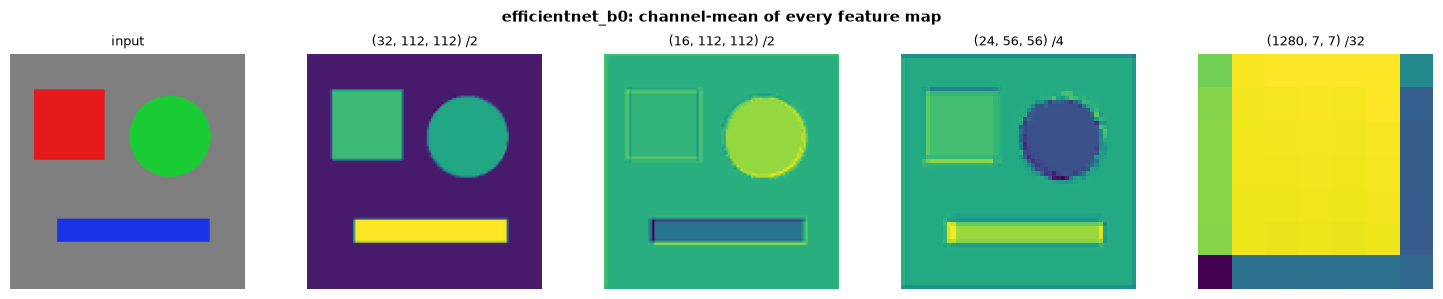

In [26]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [27]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [28]:
# ── Code Walkthrough ──────────────────────────────────────────────────────────
import torch, math

# 1. MBConvB building block
block = MBConvB(in_chs=32, out_chs=16, stride=1, expand_ratio=1, kernel_size=3)
x = torch.randn(2, 32, 56, 56)
y = block(x)
print('MBConvB(32→16, ratio=1, k=3, s=1):')
print(f'  Input:  {tuple(x.shape)}')
print(f'  Output: {tuple(y.shape)}')
print(f'  Has skip: {block.has_skip}')

# 2. Compound scaling
dm, wm = 1.4, 1.2  # B3 coefficients
print('\nB3 scaling (B0 stage 4: out=80, blocks=3):')
scaled_out = _make_divisible(80 * wm, 8)
scaled_blk = max(1, math.ceil(3 * dm))
print(f'  Width-scaled channels: {scaled_out}')
print(f'  Depth-scaled blocks:   {scaled_blk}')

MBConvB(32→16, ratio=1, k=3, s=1):
  Input:  (2, 32, 56, 56)
  Output: (2, 16, 56, 56)
  Has skip: False

B3 scaling (B0 stage 4: out=80, blocks=3):
  Width-scaled channels: 96
  Depth-scaled blocks:   5


In [29]:
# ── Usage Example ─────────────────────────────────────────────────────────────

print('EfficientNet-B series backbone outputs:')
for name in ['efficientnet_b0', 'efficientnet_b3', 'efficientnet_b7']:
    b = build_vision_backbone(name)
    b.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = b(x)
    print(f'\n{name}:')
    print(f'  embed_dim: {b.embed_dim}')
    print(f'  pooled:    {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params:    {b.num_parameters():,}')

EfficientNet-B series backbone outputs:



efficientnet_b0:
  embed_dim: 1280
  pooled:    (1, 1280)
  feature_maps: [(1, 32, 112, 112), (1, 16, 112, 112), (1, 24, 56, 56), (1, 1280, 7, 7)]
  params:    7,142,848



efficientnet_b3:
  embed_dim: 1536
  pooled:    (1, 1536)
  feature_maps: [(1, 40, 112, 112), (1, 16, 112, 112), (1, 32, 56, 56), (1, 1536, 7, 7)]
  params:    19,982,202



efficientnet_b7:
  embed_dim: 2560
  pooled:    (1, 2560)
  feature_maps: [(1, 64, 112, 112), (1, 32, 112, 112), (1, 48, 56, 56), (1, 2560, 7, 7)]
  params:    123,283,160


## References

| # | Citation |
|---|----------|
| [1] | Tan, M. & Le, Q. V. (2019). **EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.** ICML. arXiv:1905.11946. |
| [2] | Tan, M. & Le, Q. V. (2021). **EfficientNetV2: Smaller Models and Faster Training.** ICML. arXiv:2104.00298. |
| [3] | Sandler, M. et al. (2018). **MobileNetV2: Inverted Residuals and Linear Bottlenecks.** CVPR. arXiv:1801.04381. |
| [4] | Zoph, B. et al. (2018). **Learning Transferable Architectures for Scalable Image Recognition (NASNet).** CVPR. |
| [5] | Hu, J. et al. (2018). **Squeeze-and-Excitation Networks.** CVPR. arXiv:1709.01507. |
| [6] | Huang, G. et al. (2016). **Deep Networks with Stochastic Depth.** ECCV. |

---
*Notebook: EfficientNet B0-B7 — HaleBlocks backbone family*  
*Architecture: `hale_core.nn.vision.cnn.efficientnet_b`*